In [1]:
import json
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

In [2]:
def find_repo_root():
    """Find the actual project root even when the notebook runs from a workspace parent folder."""
    start = Path.cwd().resolve()
    search_roots = [start, *start.parents]

    for root in search_roots:
        repo_candidates = [root, root / "ProjetoIA025"]
        for candidate in repo_candidates:
            if (candidate / "nlp_34_treinar_unet.py").exists() or (candidate / "pipeline").exists():
                return candidate
    return start

ROOT = find_repo_root()
DATASET_CANDIDATES = [
    ROOT / "DATASET_UNET",
    ROOT / "DATASET_UNET" / "DATASET_UNET",
    ROOT / "data" / "DATASET_UNET",
]

DATASET_DIR = next(
    (p for p in DATASET_CANDIDATES if (p / "manifest.json").exists() and (p / "patches").exists()),
    ROOT / "DATASET_UNET"
)
PATCH_DIR = DATASET_DIR / "patches"

BATCH_SIZE = 4
PATCH_SHAPE = (256, 256)
PATCH_FILES = sorted(PATCH_DIR.glob("*.npz"))

print(f"Repo root: {ROOT}")
print(f"Dataset dir: {DATASET_DIR}")
print(f"Patch files found: {len(PATCH_FILES)}")
print(f"Sample patch list: {[p.name for p in PATCH_FILES[:5]]}")


Repo root: C:\Users\danil\OneDrive\Projetos\ProjetoIA025
Dataset dir: C:\Users\danil\OneDrive\Projetos\ProjetoIA025\DATASET_UNET\DATASET_UNET
Patch files found: 1458
Sample patch list: ['20130107_y0000_x0000.npz', '20130107_y0000_x0256.npz', '20130107_y0000_x0768.npz', '20130107_y0256_x0256.npz', '20130107_y0256_x0512.npz']


In [3]:
print(f"Patch directory exists: {PATCH_DIR.exists()}")
if not PATCH_DIR.exists():
    raise FileNotFoundError(f"No patch directory found. Expected one of: {[str(p) for p in DATASET_CANDIDATES]}")

manifest_path = DATASET_DIR / "manifest.json"
if not manifest_path.exists():
    raise FileNotFoundError(f"Manifest not found: {manifest_path}")

manifest = json.loads(manifest_path.read_text(encoding="utf-8"))
print("Manifest loaded successfully.")
print("Dataset channels:", manifest.get("canais", []))
print("Patch size:", manifest.get("patch", {}).get("tamanho"))


Patch directory exists: True
Manifest loaded successfully.
Dataset channels: ['precip_total_mm', 'precip_max_mmh', 'lulc_idx', 'imperv', 'decl_pct', 'susc_via', 'hand_m', 'log_area_contrib', 'cota_m', 'mascara_valida']
Patch size: 256


In [4]:
def load_patch_batch(paths, max_items=None):
    """Load a list of .npz patches into a Python list of dictionaries."""
    items = []
    for p in paths[:max_items] if max_items else paths:
        with np.load(p, allow_pickle=False) as data:
            item = {
                "path": str(p),
                "name": p.name,
                "X": np.asarray(data["X"], dtype=np.float32),
                "y": np.asarray(data["y"], dtype=np.float32),
                "valido": np.asarray(data.get("valido", np.ones_like(data["y"])), dtype=np.float32),
            }
            for key in ("date", "precip_val", "frac_valida"):
                if key in data.files:
                    value = data[key]
                    item[key] = value.item() if value.ndim == 0 else value.tolist()
            items.append(item)
    return items

sample_paths = PATCH_FILES[:BATCH_SIZE]
patch_batch = load_patch_batch(sample_paths, max_items=BATCH_SIZE)

print(f"Loaded batch size: {len(patch_batch)}")
print("First patch keys:", list(patch_batch[0].keys()))
print("First patch X shape:", patch_batch[0]["X"].shape)
print("First patch y shape:", patch_batch[0]["y"].shape)
print("First patch valid shape:", patch_batch[0]["valido"].shape)


Loaded batch size: 4
First patch keys: ['path', 'name', 'X', 'y', 'valido', 'date', 'precip_val', 'frac_valida']
First patch X shape: (10, 256, 256)
First patch y shape: (256, 256)
First patch valid shape: (256, 256)


In [5]:
def normalize_patch_channels(X, manifest, eps=1e-8):
    """Normalize each channel using the manifest ranges if available."""
    X = X.copy().astype(np.float32)
    ranges = manifest.get("normalizacao", {})
    channels = manifest.get("canais_fisicos", [])

    for idx, channel_name in enumerate(channels[: X.shape[0]]):
        if channel_name not in ranges:
            continue
        lo, hi = ranges[channel_name]
        if hi <= lo:
            continue
        X[idx] = (X[idx] - lo) / (hi - lo + eps)

    return X

first_patch = patch_batch[0]
X_norm = normalize_patch_channels(first_patch["X"], manifest)

print("First channel min/max after normalization:", float(X_norm[0].min()), float(X_norm[0].max()))
print("Target mask unique values:", np.unique(first_patch["y"]))
print("Valid mask unique values:", np.unique(first_patch["valido"]))


First channel min/max after normalization: 0.0003024053876288235 0.00031086118542589247
Target mask unique values: [0.]
Valid mask unique values: [0. 1.]


In [6]:
def load_patch(path):
    with np.load(path, allow_pickle=False) as data:
        X = np.asarray(data["X"], dtype=np.float32)
        y = np.asarray(data["y"], dtype=np.float32)
        valid = np.asarray(data.get("valido", np.ones_like(y)), dtype=np.float32)
        return X, y, valid

def filter_positive_target_paths(paths, min_positive=1):
    usable = []
    for p in paths:
        try:
            _, y, _ = load_patch(p)
            if int(np.sum(y > 0)) >= min_positive:
                usable.append(p)
        except Exception:
            continue
    return usable

usable_paths = filter_positive_target_paths(PATCH_FILES, min_positive=1)

if not usable_paths:
    usable_paths = PATCH_FILES[:BATCH_SIZE]
    print("No flood-positive patches found in this sample. Falling back to the first batch of files.")
else:
    print(f"Found {len(usable_paths)} flood-positive patches.")
    print("Example files:", [p.name for p in usable_paths[:5]])

sample_paths = usable_paths[:BATCH_SIZE]
print("Selected paths:", [p.name for p in sample_paths])

Found 951 flood-positive patches.
Example files: ['20130107_y0000_x0768.npz', '20130107_y0256_x0256.npz', '20130107_y0256_x0512.npz', '20130107_y0256_x0768.npz', '20130107_y0512_x0256.npz']
Selected paths: ['20130107_y0000_x0768.npz', '20130107_y0256_x0256.npz', '20130107_y0256_x0512.npz', '20130107_y0256_x0768.npz']


In [7]:
def normalize_patch_channels(X, manifest, eps=1e-8):
    X = X.copy().astype(np.float32)
    ranges = manifest.get("normalizacao", {})
    channels = manifest.get("canais_fisicos", [])

    for idx, channel_name in enumerate(channels[: X.shape[0]]):
        if channel_name not in ranges:
            continue
        lo, hi = ranges[channel_name]
        if hi <= lo:
            continue
        X[idx] = (X[idx] - lo) / (hi - lo + eps)

    return X

batch = []
for p in sample_paths:
    X, y, valid = load_patch(p)
    X = normalize_patch_channels(X, manifest)
    batch.append({"path": str(p), "name": p.name, "X": X, "y": y, "valido": valid})

print(f"Loaded normalized batch size: {len(batch)}")
for item in batch[:2]:
    print(item["name"], "X shape:", item["X"].shape, "y unique:", np.unique(item["y"]), "valid unique:", np.unique(item["valido"]))


Loaded normalized batch size: 4
20130107_y0000_x0768.npz X shape: (10, 256, 256) y unique: [0. 1.] valid unique: [0. 1.]
20130107_y0256_x0256.npz X shape: (10, 256, 256) y unique: [0. 1.] valid unique: [0. 1.]


In [8]:
def apply_random_augmentation(X, y, valid, seed=None):
    rng = np.random.RandomState(seed)
    mode = rng.choice(["identity", "flip_h", "flip_v", "rot_90", "rot_180", "rot_270"])

    if mode == "flip_h":
        X = X[:, :, ::-1]
        y = y[:, ::-1]
        valid = valid[:, ::-1]
    elif mode == "flip_v":
        X = X[:, ::-1, :]
        y = y[::-1, :]
        valid = valid[::-1, :]
    elif mode == "rot_90":
        X = np.rot90(X, axes=(1, 2))
        y = np.rot90(y, k=1)
        valid = np.rot90(valid, k=1)
    elif mode == "rot_180":
        X = np.rot90(X, k=2, axes=(1, 2))
        y = np.rot90(y, k=2)
        valid = np.rot90(valid, k=2)
    elif mode == "rot_270":
        X = np.rot90(X, k=3, axes=(1, 2))
        y = np.rot90(y, k=3)
        valid = np.rot90(valid, k=3)

    return X.astype(np.float32), y.astype(np.float32), valid.astype(np.float32), mode

augmented_batch = []
for idx, item in enumerate(batch):
    X, y, valid, mode = apply_random_augmentation(item["X"], item["y"], item["valido"], seed=42 + idx)
    augmented_batch.append({
        "path": item["path"],
        "name": item["name"],
        "X": X,
        "y": y,
        "valido": valid,
        "mode": mode
    })

print("Augmentation modes used:", [item["mode"] for item in augmented_batch])
for item in augmented_batch[:2]:
    print(item["name"], "augmented X shape:", item["X"].shape, "augmented y unique:", np.unique(item["y"]))


Augmentation modes used: [np.str_('rot_90'), np.str_('rot_180'), np.str_('rot_180'), np.str_('rot_90')]
20130107_y0000_x0768.npz augmented X shape: (10, 256, 256) augmented y unique: [0. 1.]
20130107_y0256_x0256.npz augmented X shape: (10, 256, 256) augmented y unique: [0. 1.]


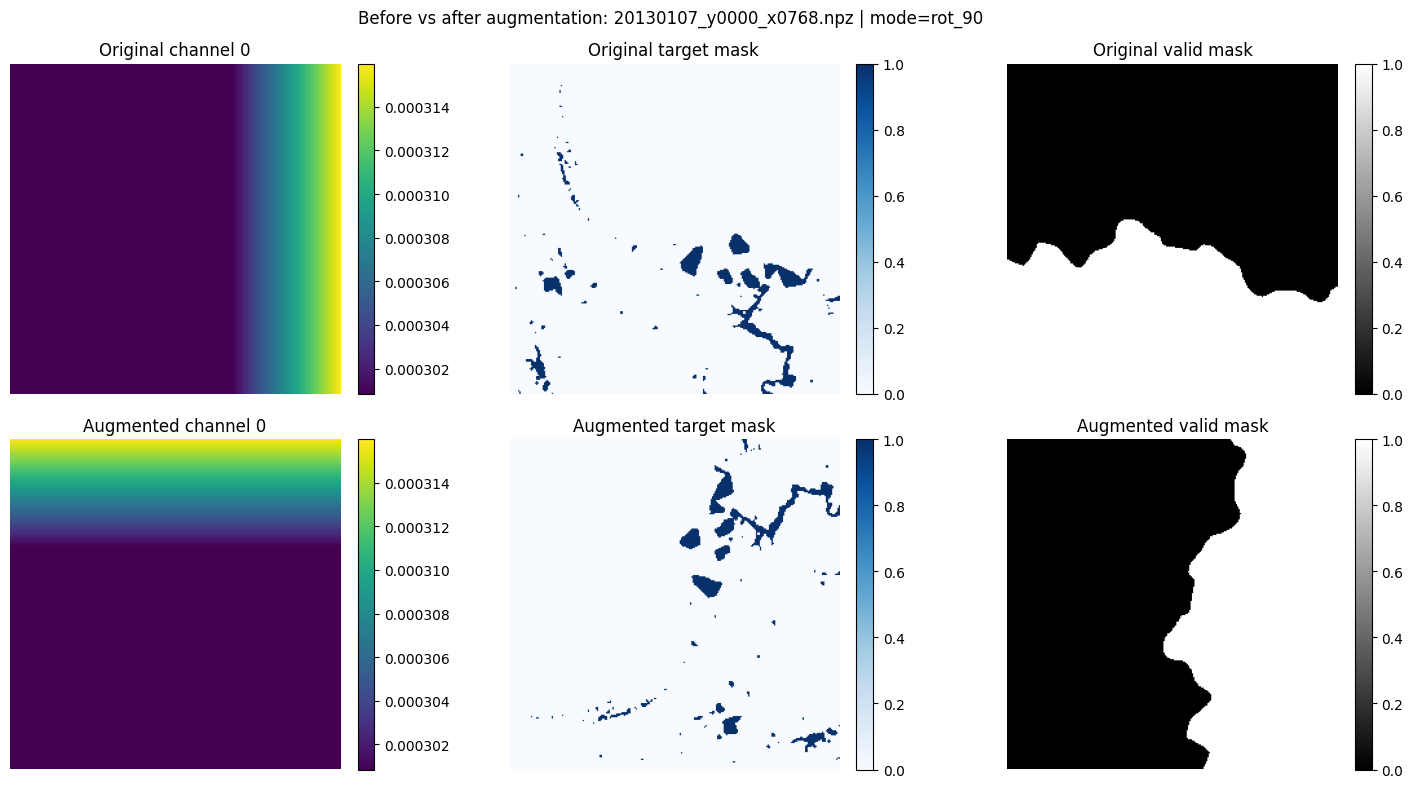

In [9]:
def preview_before_after(before_patch, after_patch, title="Before vs after augmentation"):
    fig, axes = plt.subplots(2, 3, figsize=(15, 8))
    items = [
        ("Original channel 0", before_patch["X"][0], "viridis"),
        ("Original target mask", before_patch["y"], "Blues"),
        ("Original valid mask", before_patch["valido"], "gray"),
        ("Augmented channel 0", after_patch["X"][0], "viridis"),
        ("Augmented target mask", after_patch["y"], "Blues"),
        ("Augmented valid mask", after_patch["valido"], "gray"),
    ]

    for ax, (label, arr, cmap) in zip(axes.flat, items):
        if cmap in ("Blues", "gray"):
            im = ax.imshow(arr, cmap=cmap, vmin=0, vmax=1)
        else:
            im = ax.imshow(arr, cmap=cmap)
        ax.set_title(label)
        ax.axis("off")
        fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

    fig.suptitle(f"{title}: {before_patch['name']} | mode={after_patch['mode']}")
    plt.tight_layout()
    plt.show()
    plt.close(fig)

preview_before_after(batch[0], augmented_batch[0])